# CNN Market Signal Classification
### 1D vs 2D Convolutional Networks for Financial Time-Series Direction

**Research question:** *Can convolutional neural networks learn useful short-horizon patterns in financial time series, and do the resulting predictions translate into trading value?*

**Universe:** 8 equities — Leonardo (`LDO.MI`), Thales (`HO.PA`), Prysmian (`PRY.MI`), ASML (`ASML.AS`), Repsol (`REP.MC`), UniCredit (`UCG.MI`), Siemens (`SIE.DE`) and JPMorgan (`JPM`). Seven trade primarily in European markets; JPM is the US comparator.

**Inputs:** 30 trading days × 8 OHLCV-derived features. **Task:** classify next 5-day adjusted closing-price return as **DOWN** (< −2%), **FLAT** (−2% to +2%), or **UP** (> +2%).

**Comparisons:** Majority baseline · XGBoost · 1D CNN · class-weighted 1D CNN · class-weighted 2D CNN. **Primary metric:** validation Macro-F1.

> **Recorded outcome (2022–2023 validation):** weighted 2D CNN **0.3640** Macro-F1, weighted 1D CNN **0.3637**, XGBoost **0.3399**. A long/cash strategy based on the weighted **1D CNN** beat Buy & Hold in **3 of 8** stocks in this *exploratory* comparison. The overall classification signal is weak; this is **not** evidence of a reliably profitable strategy.
>
> The charts and tables embedded below are preserved from the supplied executed notebook. Re-running may alter model results. The `2024–2026` period was already examined during development and must **not** be described as an untouched confirmatory test.


## 0 · Environment and plotting style

Install libraries **once** in the selected VS Code/Jupyter kernel if needed:

```python
%pip install yfinance pandas numpy matplotlib seaborn scikit-learn xgboost tensorflow
```

Run the following cells **top to bottom** after restarting the kernel. No `src/`, external Python modules or project-root tricks are required. TensorFlow on native Windows normally runs on CPU in this setup.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    confusion_matrix, classification_report
)
from xgboost import XGBClassifier

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

TICKERS = [
    "LDO.MI", "HO.PA", "PRY.MI", "ASML.AS",
    "REP.MC", "UCG.MI", "SIE.DE", "JPM"
]
CLASS_NAMES = ["DOWN", "FLAT", "UP"]
PALETTE = sns.color_palette("Set2", 8)

sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette=PALETTE,
    rc={
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.alpha": 0.20,
        "lines.linewidth": 0.8
    }
)
pd.set_option("display.max_columns", 30)

print("TensorFlow:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))
print("Tickers:", TICKERS)

TensorFlow: 2.21.0
GPU available: False
Tickers: ['LDO.MI', 'HO.PA', 'PRY.MI', 'ASML.AS', 'REP.MC', 'UCG.MI', 'SIE.DE', 'JPM']


## 1 · Load and audit real market data

The experiment uses daily Yahoo Finance **OHLCV** data, with adjusted historical prices (`auto_adjust=True`). It tries the local `market_data.csv` first, so reruns reuse the **same price snapshot** instead of silently refreshing research results. If no CSV exists, it downloads and saves the data.

The last date is exclusive. The fixed upper bound below reflects the **October 2026 dataset already explored**; it is not a live market data pipeline. Open the notebook from the folder where you want `market_data.csv` to be stored. Keep this CSV locally; for GitHub, only the notebook and README are necessary.

In [2]:
DATA_FILE = Path("market_data.csv")
START_DATE = "2015-01-01"
END_DATE = "2026-10-19"  # exclusive, reproducible historical snapshot
OHLCV = ["Open", "High", "Low", "Close", "Volume"]

if DATA_FILE.exists():
    print(f"Loading existing snapshot: {DATA_FILE.resolve()}")
    df = pd.read_csv(DATA_FILE)
else:
    print("Downloading Yahoo Finance historical data...")
    datasets = []
    for ticker in TICKERS:
        prices = yf.download(
            ticker,
            start=START_DATE,
            end=END_DATE,
            interval="1d",
            auto_adjust=True,
            progress=False
        )
        if prices.empty:
            warnings.warn(f"No observations downloaded for {ticker}")
            continue
        if isinstance(prices.columns, pd.MultiIndex):
            prices.columns = prices.columns.get_level_values(0)
        prices = prices.reset_index()
        prices["Ticker"] = ticker
        datasets.append(prices[["Date", "Ticker", *OHLCV]])

    if not datasets:
        raise ValueError("No price series returned. Provide market_data.csv or check the connection.")
    df = pd.concat(datasets, ignore_index=True)
    df.to_csv(DATA_FILE, index=False)
    print(f"Saved a reproducible snapshot to {DATA_FILE.resolve()}")

required = {"Date", "Ticker", *OHLCV}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

df["Date"] = pd.to_datetime(df["Date"], utc=True).dt.tz_localize(None)
df["Ticker"] = df["Ticker"].astype(str)
df = df[df["Ticker"].isin(TICKERS)].copy()
df[OHLCV] = df[OHLCV].apply(pd.to_numeric, errors="coerce")
df = df.sort_values(["Ticker", "Date"]).reset_index(drop=True)

if df.duplicated(["Ticker", "Date"]).any():
    raise ValueError("Duplicate ticker-date entries found in market_data.csv")
missing_tickers = sorted(set(TICKERS) - set(df["Ticker"]))
if missing_tickers:
    raise ValueError(f"Missing tickers in the dataset: {missing_tickers}")

print(f"Loaded {len(df):,} observations | {df['Ticker'].nunique()} stocks")
display(df.head())

Saved a reproducible snapshot to C:\Users\zedax\Downloads\market_data.csv
Loaded 24,011 observations | 8 stocks


Price,Date,Ticker,Open,High,Low,Close,Volume
0,2015-01-02,ASML.AS,80.216506,80.716741,79.278560,79.618004,856700
1,2015-01-05,ASML.AS,79.242864,80.171876,77.947610,78.153061,1503799
2,2015-01-06,ASML.AS,78.010122,78.161978,75.633995,75.633995,1601221
3,2015-01-07,ASML.AS,76.062770,76.473677,75.732254,75.884109,1406733
4,2015-01-08,ASML.AS,76.866733,78.957004,76.223570,78.778351,1504006


### 1.1 · Quality checks and coverage

In [3]:
audit = df.groupby("Ticker").agg(
    observations=("Close", "count"),
    first_date=("Date", "min"),
    last_date=("Date", "max"),
    min_price=("Close", "min"),
    max_price=("Close", "max")
).reindex(TICKERS)

display(audit)
print("Missing values by column:")
display(df.isna().sum())

if df[OHLCV].isna().any().any():
    raise ValueError("Missing OHLCV values detected. Inspect the source before modeling.")
if (df[["Open", "High", "Low", "Close"]] <= 0).any().any():
    raise ValueError("Non-positive stock prices detected.")

,observations,first_date,last_date,min_price,max_price
Ticker,,,,,
LDO.MI,2998,2015-01-02,2026-10-16,3.839301,63.491226
HO.PA,3019,2015-01-02,2026-10-16,35.818935,271.899994
PRY.MI,2998,2015-01-02,2026-10-16,11.333576,156.899994
ASML.AS,3018,2015-01-02,2026-10-16,64.544670,1719.329468
REP.MC,3017,2015-01-02,2026-10-16,3.636186,31.540001
UCG.MI,2998,2015-01-02,2026-10-16,4.712502,86.150002
SIE.DE,2998,2015-01-02,2026-10-16,46.991302,289.850006
JPM,2965,2015-01-02,2026-10-16,39.889202,363.367188


Missing values by column:


Price
Date      0
Ticker    0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

### 1.2 · Comparable historical price paths

Rebasing each stock to **100** highlights percentage changes; it does not make differently denominated prices directly interchangeable.

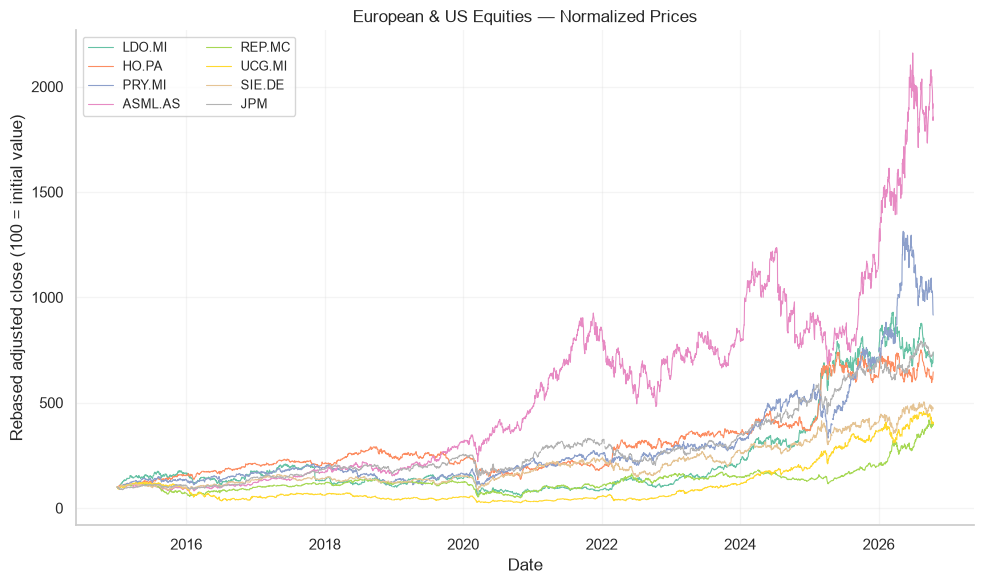

In [ ]:
prices_wide = df.pivot(index="Date", columns="Ticker", values="Close")
normalized = prices_wide.apply(lambda s: s / s.dropna().iloc[0] * 100)

fig, ax = plt.subplots(figsize=(10, 6))
for i, ticker in enumerate(TICKERS):
    ax.plot(
        normalized.index, normalized[ticker],
        label=ticker, color=PALETTE[i], linewidth=0.8)
ax.set(title="European & US Equities — Normalized Prices",
       xlabel="Date", ylabel="Rebased adjusted close (100 = initial value)")
ax.legend(ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

## 2 · Feature engineering and supervised labels

At time *t*, a model may use **only current and earlier OHLCV**. Eight features capture daily returns, recent momentum, rolling volatility, volume and intra-day price structure. Future price movements appear **only in the classification target**, never among input features.

In [5]:
df = df.sort_values(["Ticker", "Date"]).reset_index(drop=True)
g = df.groupby("Ticker", sort=False)

df["return_1d"] = g["Close"].pct_change(1, fill_method=None)
df["return_5d"] = g["Close"].pct_change(5, fill_method=None)
df["momentum_10d"] = g["Close"].pct_change(10, fill_method=None)
df["volatility_20d"] = g["return_1d"].transform(lambda x: x.rolling(20).std())
df["volume_ratio"] = df["Volume"] / g["Volume"].transform(
    lambda x: x.rolling(20).mean()
)
df["high_low_range"] = df["High"] / df["Low"] - 1
df["open_close_change"] = df["Close"] / df["Open"] - 1
df["ma_20"] = g["Close"].transform(lambda x: x.rolling(20).mean())
df["ma_gap_20"] = df["Close"] / df["ma_20"] - 1

FEATURES = [
    "return_1d", "return_5d", "momentum_10d",
    "volatility_20d", "volume_ratio", "high_low_range",
    "open_close_change", "ma_gap_20"
]
df[FEATURES] = df[FEATURES].replace([np.inf, -np.inf], np.nan)
print("Input features:", FEATURES)
display(df[["Ticker", "Date"] + FEATURES].tail(8))

Input features: ['return_1d', 'return_5d', 'momentum_10d', 'volatility_20d', 'volume_ratio', 'high_low_range', 'open_close_change', 'ma_gap_20']


Price,Ticker,Date,return_1d,return_5d,momentum_10d,volatility_20d,volume_ratio,high_low_range,open_close_change,ma_gap_20
24003,UCG.MI,2026-10-07,-0.041795,-0.062485,-0.068887,0.019739,1.177042,0.046080,-0.031406,-0.056991
24004,UCG.MI,2026-10-08,-0.030751,-0.052810,-0.083354,0.020639,1.154774,0.019192,-0.002912,-0.081269
24005,UCG.MI,2026-10-09,0.010620,-0.034496,-0.093151,0.020364,0.743183,0.013990,-0.000131,-0.066365
24006,UCG.MI,2026-10-12,0.001576,-0.044486,-0.095278,0.020410,0.524300,0.016055,-0.009483,-0.060156
24007,UCG.MI,2026-10-13,0.009836,-0.050672,-0.081146,0.020229,0.605828,0.013561,0.003911,-0.047637
24008,UCG.MI,2026-10-14,-0.002857,-0.012095,-0.073824,0.020155,0.683923,0.014158,-0.003116,-0.046738
24009,UCG.MI,2026-10-15,-0.021360,-0.002522,-0.055199,0.020289,1.208087,0.033369,-0.010404,-0.062128
24010,UCG.MI,2026-10-16,0.013974,0.000788,-0.033735,0.019800,1.006659,0.015938,0.006074,-0.046081


### 2.1 · Five-day forward classification target

For each stock, using the price after the next five **trading sessions**:

$$
r_{t,t+5}=\frac{P_{t+5}}{P_t}-1.
$$

- **Class 0 — DOWN:** $r_{t,t+5} < -0.02$.
- **Class 1 — FLAT:** $-0.02 \le r_{t,t+5} \le 0.02$.
- **Class 2 — UP:** $r_{t,t+5} > 0.02$.

These categories are **targets**, constructed using future prices for supervised training/evaluation. Future prices must never enter the *input* at time $t$. The ±2% choice is a fixed research convention, not a calibrated profit threshold.


In [6]:
HORIZON = 5
THRESHOLD = 0.02

g = df.groupby("Ticker", sort=False)
df["future_return"] = g["Close"].shift(-HORIZON) / df["Close"] - 1
df["target_date"] = g["Date"].shift(-HORIZON)
df["signal"] = pd.Series(pd.NA, index=df.index, dtype="Int64")
valid_target = df["future_return"].notna()

df.loc[valid_target, "signal"] = np.select(
    [
        df.loc[valid_target, "future_return"] < -THRESHOLD,
        df.loc[valid_target, "future_return"] > THRESHOLD
    ],
    [0, 2],
    default=1
)
print("Labeled rows:", int(df["signal"].notna().sum()))
print("Unlabeled final rows:", int(df["signal"].isna().sum()))
display(df[["Date", "Ticker", "Close", "future_return", "signal"]].dropna().head())

Labeled rows: 23971
Unlabeled final rows: 40


Price,Date,Ticker,Close,future_return,signal
0,2015-01-02,ASML.AS,79.618004,-0.036912,0
1,2015-01-05,ASML.AS,78.153061,0.004572,1
2,2015-01-06,ASML.AS,75.633995,0.051494,2
3,2015-01-07,ASML.AS,75.884109,0.028841,2
4,2015-01-08,ASML.AS,78.778351,-0.002948,1


### 2.2 · Exploratory distributions

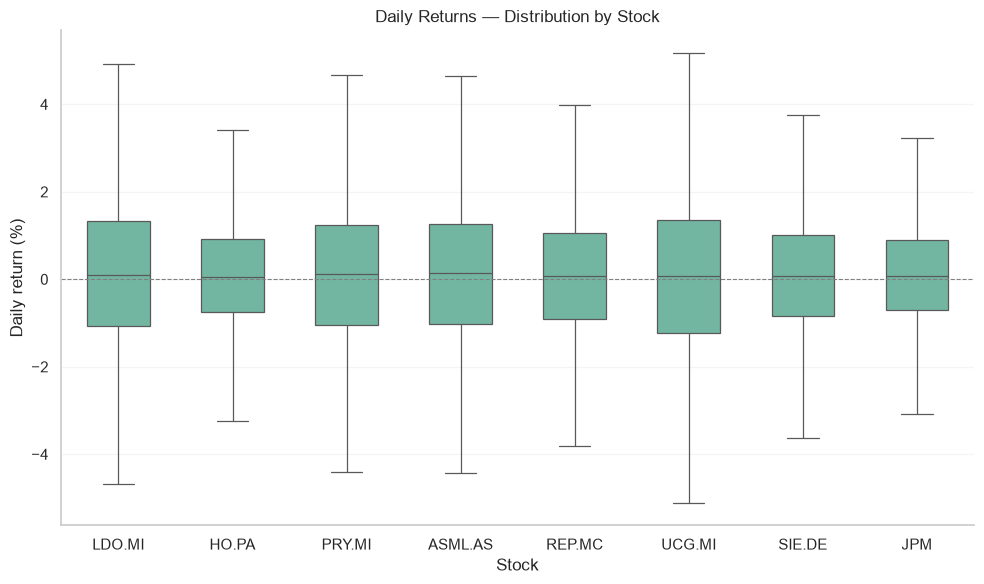

In [7]:
returns_df = df.dropna(subset=["return_1d"]).copy()
returns_df["Daily Return (%)"] = returns_df["return_1d"] * 100

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(
    data=returns_df, x="Ticker", y="Daily Return (%)",
    order=TICKERS, color=PALETTE[0], showfliers=False,
    width=0.55, linewidth=0.9, ax=ax
)
ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax.set(title="Daily Returns — Distribution by Stock", xlabel="Stock", ylabel="Daily return (%)")
plt.tight_layout()
plt.show()

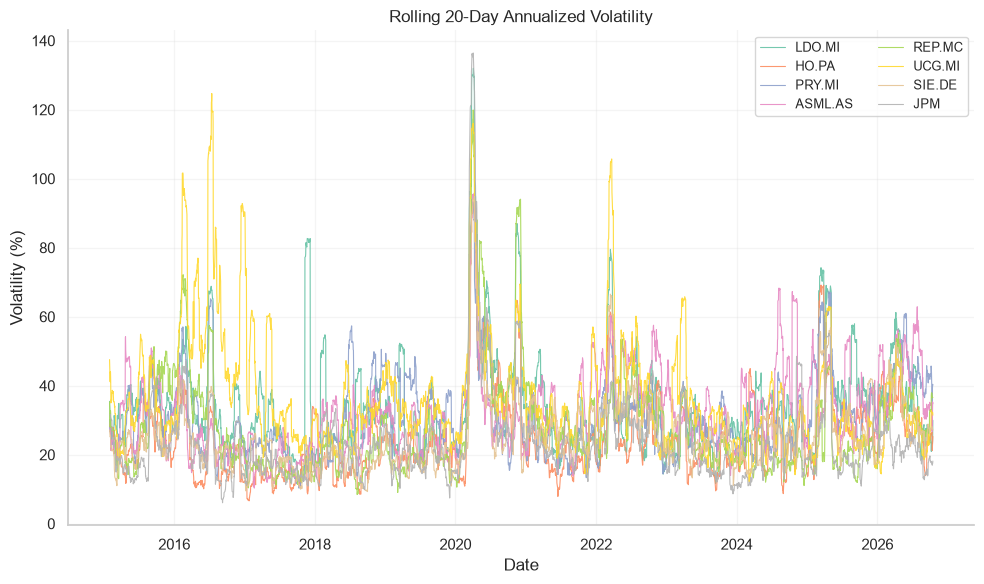

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))
for i, ticker in enumerate(TICKERS):
    stock = df[df["Ticker"] == ticker]
    annualized = stock["volatility_20d"] * np.sqrt(252) * 100
    ax.plot(stock["Date"], annualized, label=ticker,
            color=PALETTE[i], linewidth=0.8, alpha=0.9)
ax.set(title="Rolling 20-Day Annualized Volatility", xlabel="Date", ylabel="Volatility (%)")
ax.legend(ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

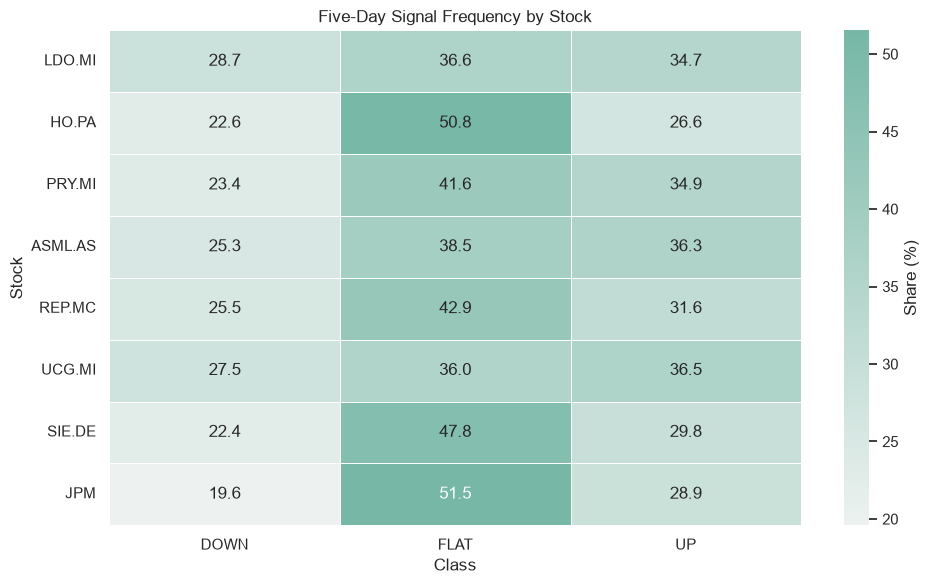

,DOWN,FLAT,UP
Ticker,,,
LDO.MI,28.70,36.55,34.75
HO.PA,22.59,50.83,26.58
PRY.MI,23.42,41.63,34.95
ASML.AS,25.26,38.47,36.28
REP.MC,25.50,42.93,31.57
UCG.MI,27.46,36.02,36.52
SIE.DE,22.35,47.84,29.80
JPM,19.59,51.52,28.89


In [9]:
signal_dist = pd.crosstab(
    df["Ticker"], df["signal"], normalize="index"
).reindex(index=TICKERS, columns=[0, 1, 2], fill_value=0) * 100
signal_dist.columns = CLASS_NAMES

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(
    signal_dist, annot=True, fmt=".1f",
    cmap=sns.light_palette("#76B7A5", as_cmap=True),
    linewidths=0.5, cbar_kws={"label": "Share (%)"}, ax=ax
)
ax.set(title="Five-Day Signal Frequency by Stock", xlabel="Class", ylabel="Stock")
plt.tight_layout()
plt.show()
display(signal_dist.round(2))

### Observation · Label imbalance

The most common class is `FLAT` for most tickers. For example, `FLAT` accounts for roughly **51%** for Thales and JPM. A model predicting `FLAT` too often can obtain reasonable accuracy while missing directional changes. **Macro-F1**, **balanced accuracy** and **per-class recall** are more informative than accuracy alone.


## 3 · Leakage-aware chronological design

| Split | Calendar window | Purpose |
|:--|:--|:--|
| Training | 2015–2021 | Fit scaler and train models |
| Validation | 2022–2023 | Compare architectures and diagnose signals |
| Previously explored holdout | 2024–2026 | **Not** a pristine final test after previous inspection |

Scaling statistics are estimated **only from training-period rows**. Each window contains exactly one ticker, and samples whose *target dates* cross a training/validation boundary are excluded. Past observations may legitimately appear in the start of a validation input window, because those data were known then.

**Important:** Adjacent 5-day labels still overlap within each split; nominal observation counts therefore overstate effective independence.


In [10]:
VAL_START = pd.Timestamp("2022-01-01")
TEST_START = pd.Timestamp("2024-01-01")
WINDOW = 30

train_feature_rows = df.loc[df["Date"] < VAL_START].dropna(subset=FEATURES)
scaler = StandardScaler().fit(train_feature_rows[FEATURES])

work = df.dropna(subset=FEATURES).sort_values(["Ticker", "Date"]).copy()
work[FEATURES] = scaler.transform(work[FEATURES])

splits = {
    split: {"X": [], "y": [], "Ticker": [], "Date": [], "TargetDate": []}
    for split in ("train", "val", "test")
}

for ticker, stock in work.groupby("Ticker", sort=False):
    stock = stock.reset_index(drop=True)
    values = stock[FEATURES].to_numpy(dtype=np.float32)
    for end in range(WINDOW - 1, len(stock)):
        row = stock.iloc[end]
        if pd.isna(row["signal"]) or pd.isna(row["target_date"]):
            continue
        date = pd.Timestamp(row["Date"])
        target_date = pd.Timestamp(row["target_date"])
        if date < VAL_START and target_date < VAL_START:
            split = "train"
        elif VAL_START <= date < TEST_START and target_date < TEST_START:
            split = "val"
        elif date >= TEST_START:
            split = "test"
        else:
            continue  # drop examples with labels overlapping a split boundary

        data = splits[split]
        data["X"].append(values[end - WINDOW + 1:end + 1])
        data["y"].append(int(row["signal"]))
        data["Ticker"].append(ticker)
        data["Date"].append(date)
        data["TargetDate"].append(target_date)

for name, data in splits.items():
    if not data["X"]:
        raise ValueError(f"No samples for split: {name}")
    data["X"] = np.stack(data["X"])
    data["y"] = np.asarray(data["y"], dtype=np.int64)
    data["Ticker"] = np.asarray(data["Ticker"])
    data["Date"] = pd.to_datetime(data["Date"])
    data["TargetDate"] = pd.to_datetime(data["TargetDate"])
    assert np.isfinite(data["X"]).all(), f"Nonfinite input in {name}"
    print(f"{name.upper():5}  X={data['X'].shape}  class counts={np.bincount(data['y'], minlength=3)}")

assert splits["train"]["TargetDate"].max() < VAL_START
assert splits["val"]["TargetDate"].max() < TEST_START
assert splits["test"]["Date"].min() >= TEST_START

TRAIN  X=(13823, 30, 8)  class counts=[3433 6280 4110]
VAL    X=(4039, 30, 8)  class counts=[1034 1633 1372]
TEST   X=(5637, 30, 8)  class counts=[1309 2265 2063]


### 3.1 · How convolution processes time

Each example has shape **30 trading days × 8 features**. A 1D kernel learns temporal templates over all 8 channels:

$$
h_{t,k}=\sigma\!\left(b_k+\sum_{j=0}^{K-1}\sum_{f=1}^{F} w_{j,f,k}\,x_{t+j,f}\right).
$$

Here $K$ is kernel width (e.g. 5 trading sessions), $F=8$ features, and $k$ indexes the learned filters. The kernel slides through time and shares its weights across positions.

For a 2D CNN, the input becomes **30 × 8 × 1**: convolution slides in both *time* and *feature index*. This representation is image-like, but neighboring feature columns do **not** imply a genuine spatial relationship. The order of features may affect its performance.


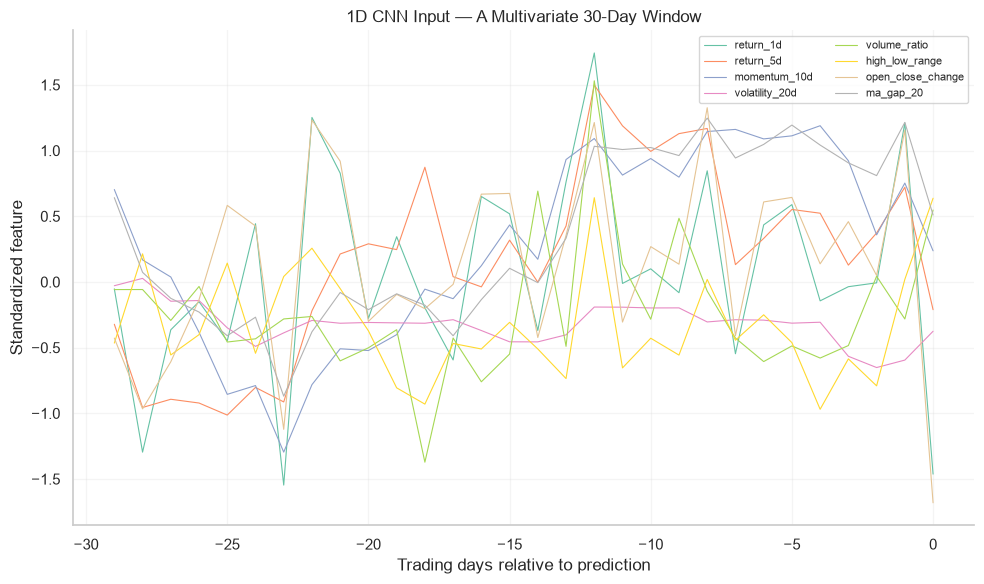

In [11]:
X_train, y_train = splits["train"]["X"], splits["train"]["y"]
X_val, y_val = splits["val"]["X"], splits["val"]["y"]
X_test, y_test = splits["test"]["X"], splits["test"]["y"]

sample = X_train[0]
fig, ax = plt.subplots(figsize=(10, 6))
for i, feature in enumerate(FEATURES):
    ax.plot(np.arange(-WINDOW + 1, 1), sample[:, i], label=feature,
            color=PALETTE[i], linewidth=0.8)
ax.set(title="1D CNN Input — A Multivariate 30-Day Window",
       xlabel="Trading days relative to prediction", ylabel="Standardized feature")
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

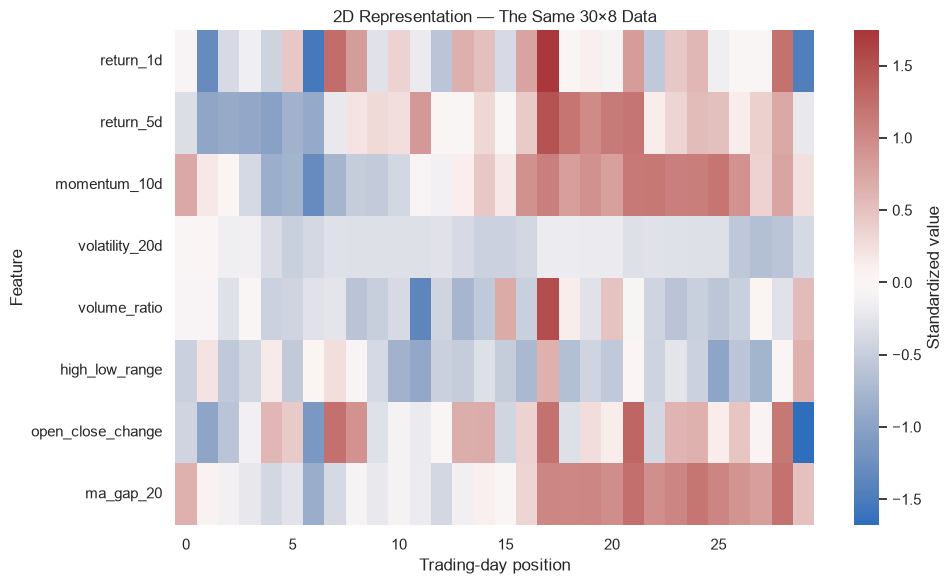

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(
    sample.T, cmap="vlag", center=0,
    xticklabels=5, yticklabels=FEATURES,
    cbar_kws={"label": "Standardized value"}, ax=ax
)
ax.set(title="2D Representation — The Same 30×8 Data",
       xlabel="Trading-day position", ylabel="Feature")
plt.tight_layout()
plt.show()

## 4 · Baselines: majority class and XGBoost

The dummy classifier always predicts the most frequent training label. XGBoost receives exactly the same numerical information as the CNNs, with the 30×8 window **flattened to 240 values**. This avoids an unfair input-information advantage.

In [13]:
X_train_flat = X_train.reshape(len(X_train), -1)
X_val_flat = X_val.reshape(len(X_val), -1)
X_test_flat = X_test.reshape(len(X_test), -1)

dummy = DummyClassifier(strategy="most_frequent").fit(X_train_flat, y_train)
xgb_model = XGBClassifier(
    objective="multi:softprob",
    num_class=3,
    n_estimators=250,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.85,
    tree_method="hist",
    random_state=SEED,
    n_jobs=-1
).fit(X_train_flat, y_train)

val_predictions = {
    "Dummy": dummy.predict(X_val_flat),
    "XGBoost": xgb_model.predict(X_val_flat)
}
print("Baseline models trained; validation predictions ready.")

Baseline models trained; validation predictions ready.


## 5 · Baseline 1D CNN

**Architecture:** `Conv1D(16, 5) → BatchNorm → MaxPool → Conv1D(32, 3) → GlobalAveragePooling → Dense(16) → Softmax(3)`.

The compact **16–32–16** design has about **2,867 parameters** in the executed output. Shared 1D filters are intended to extract local patterns over a 30-session window, not to memorise a named technical-chart pattern. We use Adam LR `0.0003`, maximum 30 epochs, and early stopping patience 6.


In [ ]:
LEARNING_RATE = 3e-4
MAX_EPOCHS = 30
PATIENCE = 6
BATCH_SIZE = 128


def make_cnn_1d():
    return keras.Sequential([
        layers.Input(shape=(WINDOW, len(FEATURES))),
        layers.Conv1D(16, kernel_size=5, padding="same",
                      activation="relu", name="first_convolution"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),
        layers.Conv1D(32, kernel_size=3, padding="same", activation="relu"),
        layers.GlobalAveragePooling1D(),
        layers.Dense(16, activation="relu"),
        layers.Dropout(0.20),
        layers.Dense(3, activation="softmax")
    ])


def configure_cnn(model):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


def early_stopping():
    return keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=PATIENCE, restore_best_weights=True)


tf.keras.utils.set_random_seed(42)
cnn_1d = configure_cnn(make_cnn_1d())
cnn_1d.summary()

history_1d = cnn_1d.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=MAX_EPOCHS, batch_size=BATCH_SIZE,
    callbacks=[early_stopping()], verbose=1)
val_predictions["CNN 1D"] = cnn_1d.predict(X_val, verbose=0).argmax(axis=1)


fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(history_1d.history["loss"], label="Training loss",
        color=PALETTE[0], linewidth=1.1)
ax.plot(history_1d.history["val_loss"], label="Validation loss",
        color=PALETTE[3], linewidth=1.1)
ax.set(title="Unweighted 1D CNN — Learning Curves", xlabel="Epoch", ylabel="Cross-entropy")
ax.legend()
plt.tight_layout()
plt.show()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ first_convolution (Conv1D)      │ (None, 30, 16)         │           656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 16)         │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 15, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 15, 32)         │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,867 (11.20 KB)

 Trainable params: 2,835 (11.07 KB)

 Non-trainable params: 32 (128.00 B)

Epoch 1/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.4587 - loss: 1.0617 - val_accuracy: 0.4219 - val_loss: 1.0777
Epoch 2/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4729 - loss: 1.0451 - val_accuracy: 0.4226 - val_loss: 1.0800
Epoch 3/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4759 - loss: 1.0414 - val_accuracy: 0.4234 - val_loss: 1.0811
Epoch 4/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4796 - loss: 1.0371 - val_accuracy: 0.4214 - val_loss: 1.0827
Epoch 5/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4838 - loss: 1.0365 - val_accuracy: 0.4246 - val_loss: 1.0821
Epoch 6/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4820 - loss: 1.0359 - val_accuracy: 0.4256 - val_loss: 1.0825
Epoch 7/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4837 - loss: 1.0340 - val_accuracy: 0.4229 - val_loss: 1.0828


Look for a **minimum in validation loss**, not for identical training/validation curves. Classification can be difficult when forward returns contain substantial noise.

## 6 · Weighted 1D CNN

Class weighting gives rare labels greater influence in the loss. The **architecture and optimizer** stay the same as in the original 1D CNN. Both models start from **new random initialization**; weighting is the experimental change.

The weighted training loss and ordinary validation loss are defined differently. Their **absolute heights need not match**. We assess improvement using *validation Macro-F1* and *per-class recall*, not curve overlap.

In [ ]:
class_weight_values = compute_class_weight(
    class_weight="balanced", classes=np.array([0, 1, 2]), y=y_train
)
class_weights = {i: float(w) for i, w in enumerate(class_weight_values)}
print("Weights:", class_weights)

tf.keras.utils.set_random_seed(43)
cnn_1d_weighted = configure_cnn(make_cnn_1d())
history_1d_weighted = cnn_1d_weighted.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    class_weight=class_weights,
    epochs=MAX_EPOCHS, batch_size=BATCH_SIZE,
    callbacks=[early_stopping()], verbose=1
)
val_predictions["CNN 1D Weighted"] = cnn_1d_weighted.predict(
    X_val, verbose=0
).argmax(axis=1)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(history_1d_weighted.history["loss"], label="Weighted training loss",
        color=PALETTE[0], linewidth=1.1)
ax.plot(history_1d_weighted.history["val_loss"], label="Unweighted validation loss",
        color=PALETTE[3], linewidth=1.1)
ax.set(title="Weighted 1D CNN — Learning Curves", xlabel="Epoch", ylabel="Loss")
ax.legend()
plt.tight_layout()
plt.show()

Weights: {0: 1.3421691426352074, 1: 0.7337048832271762, 2: 1.1210867802108677}
Epoch 1/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4071 - loss: 1.0964 - val_accuracy: 0.3565 - val_loss: 1.0981
Epoch 2/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4236 - loss: 1.0820 - val_accuracy: 0.3741 - val_loss: 1.0992
Epoch 3/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4342 - loss: 1.0756 - val_accuracy: 0.3756 - val_loss: 1.0980
Epoch 4/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4402 - loss: 1.0729 - val_accuracy: 0.3852 - val_loss: 1.0979
Epoch 5/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4394 - loss: 1.0713 - val_accuracy: 0.3798 - val_loss: 1.0982
Epoch 6/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4354 - loss: 1.0709 - val_accuracy: 0.3810 - val_loss: 1.0976
Epoch 7/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4495 - loss: 1.0683 - val_accuracy: 0.3763 - val_loss: 1.0999
Epoch 8/30
108/108 ━━━━━━

### 6.1 · Per-class recall: does weighting help?

Check whether training-class weights counteract the dominant `FLAT` label. Improved recall for `DOWN`/`UP` may come at the cost of false positives and overall accuracy. A better balanced score does not automatically imply a profitable trading signal.



CNN 1D — validation classification report
              precision    recall  f1-score   support

        DOWN       0.09      0.00      0.00      1034
        FLAT       0.43      0.80      0.56      1633
          UP       0.39      0.29      0.34      1372

    accuracy                           0.42      4039
   macro avg       0.31      0.36      0.30      4039
weighted avg       0.33      0.42      0.34      4039


CNN 1D Weighted — validation classification report
              precision    recall  f1-score   support

        DOWN       0.27      0.26      0.27      1034
        FLAT       0.48      0.37      0.42      1633
          UP       0.36      0.47      0.41      1372

    accuracy                           0.38      4039
   macro avg       0.37      0.37      0.36      4039
weighted avg       0.39      0.38      0.38      4039



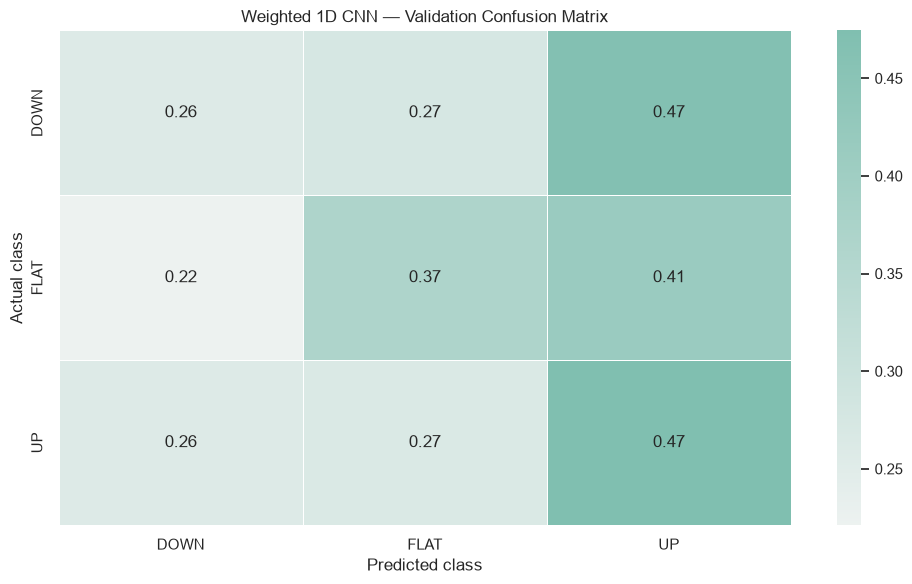

In [18]:
for model_name in ["CNN 1D", "CNN 1D Weighted"]:
    print(f"\n{model_name} — validation classification report")
    print(classification_report(
        y_val, val_predictions[model_name], labels=[0, 1, 2],
        target_names=CLASS_NAMES, zero_division=0
    ))

fig, ax = plt.subplots(figsize=(10, 6))
cm = confusion_matrix(
    y_val, val_predictions["CNN 1D Weighted"], labels=[0, 1, 2],
    normalize="true"
)
sns.heatmap(
    cm, annot=True, fmt=".2f", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
    cmap=sns.light_palette("#80BFB0", as_cmap=True),
    linewidths=0.5, ax=ax
)
ax.set(title="Weighted 1D CNN — Validation Confusion Matrix",
       xlabel="Predicted class", ylabel="Actual class")
plt.tight_layout()
plt.show()

### 6.2 · CNN activations (interpretability)

The first-layer activation map shows **which filters respond at which time steps** for one validation example. It does **not** prove the filters detect a named chart pattern or a profitable signal.

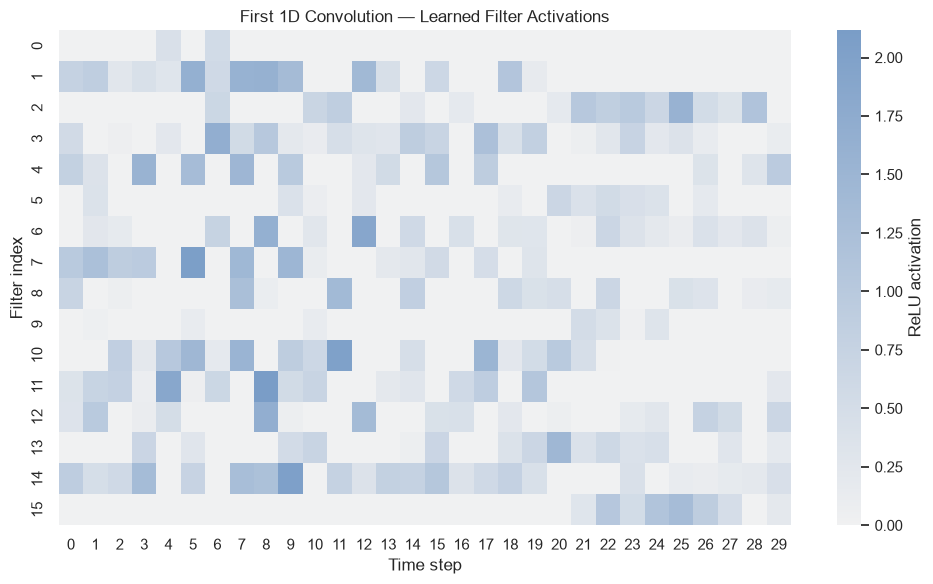

In [19]:
activation_model = keras.Model(
    inputs=cnn_1d.inputs,
    outputs=cnn_1d.get_layer("first_convolution").output
)
activations = activation_model.predict(X_val[:1], verbose=0)[0]

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(
    activations.T, cmap=sns.light_palette("#7A9DC7", as_cmap=True),
    cbar_kws={"label": "ReLU activation"}, ax=ax
)
ax.set(title="First 1D Convolution — Learned Filter Activations",
       xlabel="Time step", ylabel="Filter index")
plt.tight_layout()
plt.show()

## 7 · 2D CNN: image-like representation of a time series

The same `30×8` matrix is treated as a **single-channel image** with shape `30×8×1`. It is **not a recreation** of Sezer & Ozbayoglu's exact `15×15` technical-indicator images. We deliberately use the same input information to compare the inductive bias of **1D vs 2D convolution**.

Important: adjacent feature columns do not have a natural spatial geometry. A 2D convolution across them depends on the **arbitrary order** of the feature list. Any apparent improvement therefore requires cautious interpretation.

In [ ]:
X_train_2d = X_train[..., np.newaxis]
X_val_2d = X_val[..., np.newaxis]
X_test_2d = X_test[..., np.newaxis]

assert X_train_2d.shape[1:] == (WINDOW, len(FEATURES), 1)
print("2D input shapes:", X_train_2d.shape, X_val_2d.shape)


def make_cnn_2d():
    return keras.Sequential([
        layers.Input(shape=(WINDOW, len(FEATURES), 1)),
        layers.Conv2D(16, kernel_size=(5, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(2, 1)),
        layers.Conv2D(32, kernel_size=(3, 3), padding="same", activation="relu"),
        layers.GlobalAveragePooling2D(),
        layers.Dense(16, activation="relu"),
        layers.Dropout(0.20),
        layers.Dense(3, activation="softmax")
    ])


tf.keras.utils.set_random_seed(44)
cnn_2d_weighted = configure_cnn(make_cnn_2d())
cnn_2d_weighted.summary()

history_2d = cnn_2d_weighted.fit(
    X_train_2d, y_train,
    validation_data=(X_val_2d, y_val),
    class_weight=class_weights,
    epochs=MAX_EPOCHS, batch_size=BATCH_SIZE,
    callbacks=[early_stopping()], verbose=1
)
val_predictions["CNN 2D Weighted"] = cnn_2d_weighted.predict(
    X_val_2d, verbose=0
).argmax(axis=1)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(history_2d.history["loss"], label="Weighted training loss",
        color=PALETTE[0], linewidth=1.1)
ax.plot(history_2d.history["val_loss"], label="Unweighted validation loss",
        color=PALETTE[3], linewidth=1.1)
ax.set(title="Weighted 2D CNN — Learning Curves", xlabel="Epoch", ylabel="Loss")
ax.legend()
plt.tight_layout()
plt.show()

2D input shapes: (13823, 30, 8, 1) (4039, 30, 8, 1)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 8, 16)      │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 30, 8, 16)      │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 8, 16)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 15, 8, 32)      │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,539 (21.64 KB)

 Trainable params: 5,507 (21.51 KB)

 Non-trainable params: 32 (128.00 B)

Epoch 1/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.3644 - loss: 1.1101 - val_accuracy: 0.2642 - val_loss: 1.1030
Epoch 2/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4064 - loss: 1.0857 - val_accuracy: 0.3303 - val_loss: 1.0994
Epoch 3/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4138 - loss: 1.0817 - val_accuracy: 0.3731 - val_loss: 1.0952
Epoch 4/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4247 - loss: 1.0793 - val_accuracy: 0.3746 - val_loss: 1.0950
Epoch 5/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4283 - loss: 1.0784 - val_accuracy: 0.3706 - val_loss: 1.0958
Epoch 6/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4330 - loss: 1.0770 - val_accuracy: 0.3689 - val_loss: 1.0986
Epoch 7/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4329 - loss: 1.0768 - val_accuracy: 0.3682 - val_loss: 1.0971
Epoch 8/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4370 - loss: 1.0769 - val_accuracy: 0.

## 8 · Validation model comparison

All five models use the same historical data and class definitions. We rank using **Macro-F1**, which weights DOWN, FLAT and UP equally. These are **validation results**, used during development; do not label them independent out-of-sample trading evidence.


,Model,Accuracy,Balanced Accuracy,Macro-F1
0,CNN 2D Weighted,0.3746,0.3663,0.3640
1,CNN 1D Weighted,0.3758,0.3668,0.3637
2,XGBoost,0.4159,0.3695,0.3399
3,CNN 1D,0.4219,0.3636,0.2996
4,Dummy,0.4043,0.3333,0.1919


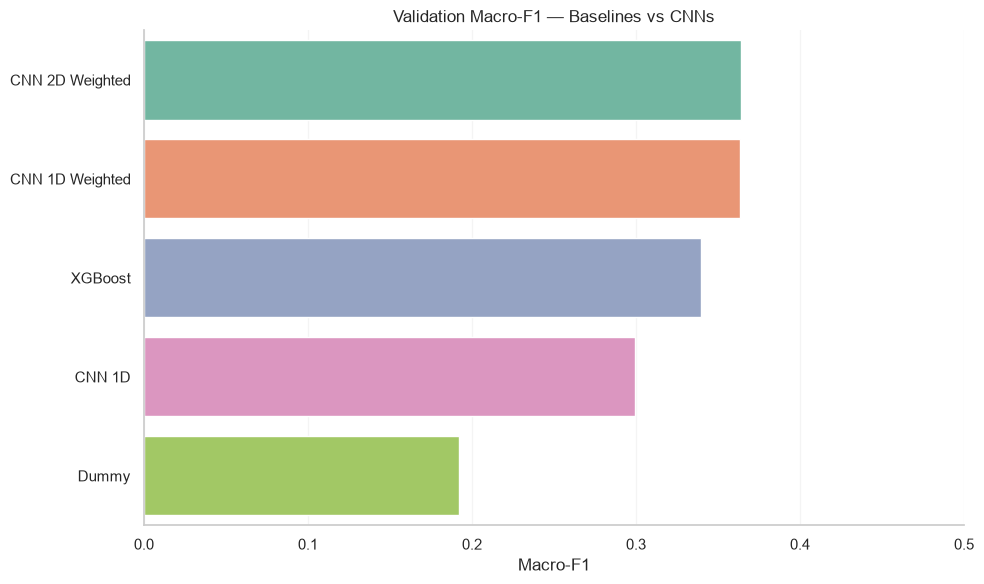

In [22]:
evaluation_rows = []
for name, pred in val_predictions.items():
    evaluation_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, pred),
        "Balanced Accuracy": balanced_accuracy_score(y_val, pred),
        "Macro-F1": f1_score(
            y_val, pred, labels=[0, 1, 2], average="macro", zero_division=0
        )
    })
comparison_df = pd.DataFrame(evaluation_rows).sort_values(
    "Macro-F1", ascending=False
).reset_index(drop=True)
display(comparison_df.round(4))

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=comparison_df, x="Macro-F1", y="Model", hue="Model",
    palette="Set2", legend=False, ax=ax
)
ax.set(title="Validation Macro-F1 — Baselines vs CNNs", xlabel="Macro-F1", ylabel="")
ax.set_xlim(0, max(0.5, float(comparison_df["Macro-F1"].max()) + 0.05))
plt.tight_layout()
plt.show()

### Research finding 1 · Two weighted CNNs are practically tied

In the saved execution, the 2D weighted model achieved **0.3640 Macro-F1**, versus **0.3637** for the 1D weighted model and **0.3399** for XGBoost. The difference between weighted CNNs is just **0.0003**: too small for a robust superiority claim without multi-seed and walk-forward checks. Their **balanced accuracies (~0.366)** are also only moderately above **1/3**, the reference for uniform three-class guessing. XGBoost maintains higher raw accuracy (**0.4159**) because it prioritizes the more common class.

### 8.1 · 2D CNN classification report and confusion matrix

              precision    recall  f1-score   support

        DOWN       0.27      0.34      0.30      1034
        FLAT       0.45      0.46      0.46      1633
          UP       0.38      0.30      0.33      1372

    accuracy                           0.37      4039
   macro avg       0.37      0.37      0.36      4039
weighted avg       0.38      0.37      0.38      4039



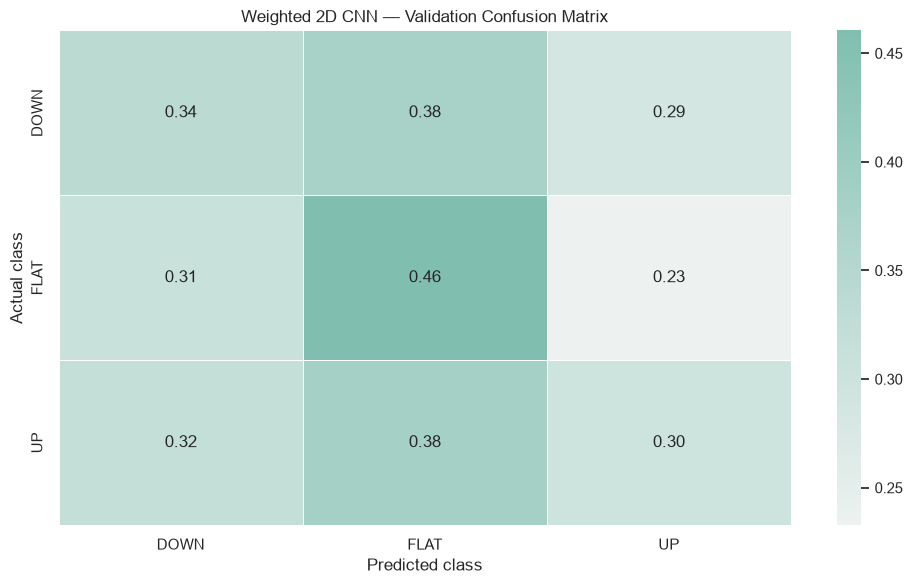

In [23]:
print(classification_report(
    y_val, val_predictions["CNN 2D Weighted"],
    labels=[0, 1, 2], target_names=CLASS_NAMES, zero_division=0
))

cm = confusion_matrix(
    y_val, val_predictions["CNN 2D Weighted"],
    labels=[0, 1, 2], normalize="true"
)
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(
    cm, annot=True, fmt=".2f", cmap=sns.light_palette("#80BFB0", as_cmap=True),
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, linewidths=0.5, ax=ax
)
ax.set(title="Weighted 2D CNN — Validation Confusion Matrix",
       xlabel="Predicted class", ylabel="Actual class")
plt.tight_layout()
plt.show()

### 8.2 · Per-stock generalization

Models are **pooled models trained across all eight stocks**, not separately optimized for each ticker. Breakdown by ticker is descriptive; picking the best model *for each stock* from the same validation period would add selection bias.


Model,CNN 1D,CNN 1D Weighted,CNN 2D Weighted,Dummy,XGBoost
Ticker,,,,,
LDO.MI,0.247,0.338,0.330,0.188,0.328
HO.PA,0.303,0.293,0.306,0.217,0.291
PRY.MI,0.322,0.349,0.362,0.203,0.293
ASML.AS,0.294,0.341,0.372,0.168,0.365
REP.MC,0.305,0.328,0.388,0.190,0.351
UCG.MI,0.326,0.414,0.389,0.172,0.369
SIE.DE,0.260,0.374,0.315,0.190,0.330
JPM,0.264,0.376,0.294,0.204,0.297


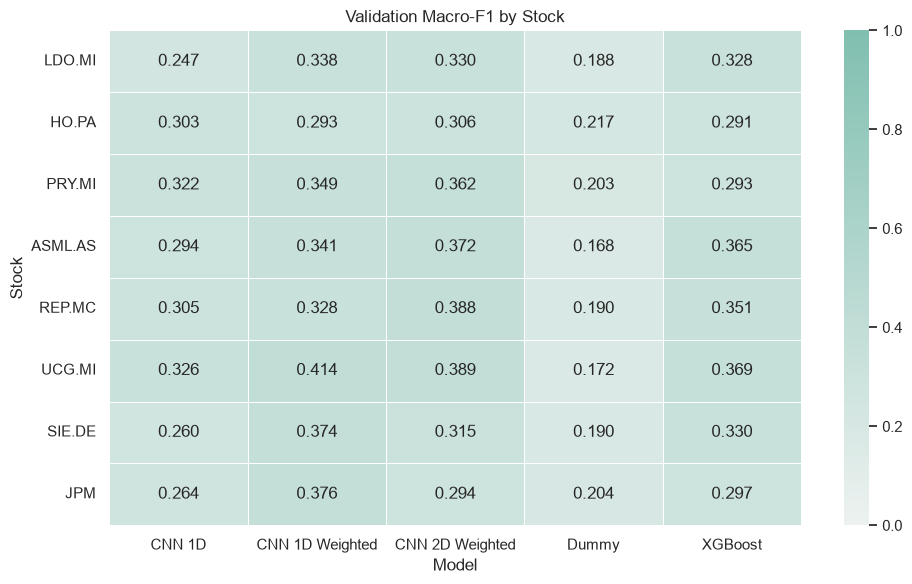

In [24]:
per_stock_rows = []
for ticker in TICKERS:
    mask = splits["val"]["Ticker"] == ticker
    for model_name, pred in val_predictions.items():
        per_stock_rows.append({
            "Ticker": ticker,
            "Model": model_name,
            "Macro-F1": f1_score(
                y_val[mask], pred[mask], labels=[0, 1, 2],
                average="macro", zero_division=0
            )
        })
per_stock_df = pd.DataFrame(per_stock_rows).pivot(
    index="Ticker", columns="Model", values="Macro-F1"
).reindex(TICKERS)
display(per_stock_df.round(3))

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(
    per_stock_df, annot=True, fmt=".3f",
    cmap=sns.light_palette("#80BFB0", as_cmap=True),
    vmin=0, vmax=1, linewidths=0.5, ax=ax
)
ax.set(title="Validation Macro-F1 by Stock", xlabel="Model", ylabel="Stock")
plt.tight_layout()
plt.show()

### Research finding 2 · Differences depend on the stock

The **weighted 1D CNN** has the highest validation Macro-F1 for Leonardo, UniCredit, Siemens and JPMorgan; the **weighted 2D CNN** leads for Thales, Prysmian, ASML and Repsol. These per-stock comparisons describe the same validation set and are **not** an independent ranking study. The best observed individual result is weighted 1D CNN on UniCredit (**0.414 Macro-F1**).

## 9 · Classification diagnostics: per-class recall

The weighted **2D** model reaches **DOWN recall 0.339**, versus **0.259** for weighted 1D and **0.085** for XGBoost. The weighted **1D** model reaches **UP recall 0.474**, compared with **0.299** for weighted 2D. The 2D model is not uniformly better across classes.

,DOWN,FLAT,UP
Model,,,
XGBoost,0.085,0.720,0.303
CNN 1D Weighted,0.259,0.367,0.474
CNN 2D Weighted,0.339,0.461,0.299


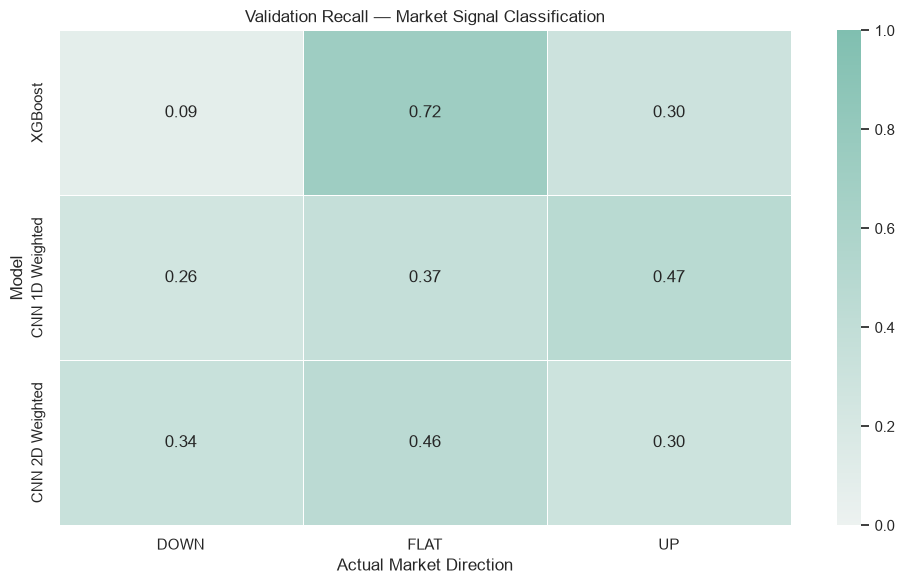

In [26]:
from sklearn.metrics import recall_score

rows = []

for name in ["XGBoost", "CNN 1D Weighted", "CNN 2D Weighted"]:

    recalls = recall_score(
        y_val,
        val_predictions[name],
        labels=[0, 1, 2],
        average=None,
        zero_division=0
    )

    rows.append({
        "Model": name,
        "DOWN": recalls[0],
        "FLAT": recalls[1],
        "UP": recalls[2]
    })

recall_df = pd.DataFrame(rows).set_index("Model")

display(recall_df.round(3))

fig, ax = plt.subplots(figsize=(10, 6))

sns.heatmap(
    recall_df,
    annot=True,
    fmt=".2f",
    cmap=sns.light_palette("#80BFB0", as_cmap=True),
    vmin=0,
    vmax=1,
    linewidths=0.5,
    ax=ax
)

ax.set_title("Validation Recall — Market Signal Classification")
ax.set_xlabel("Actual Market Direction")
ax.set_ylabel("Model")

plt.tight_layout()
plt.show()

### 9.1 · Signal quality and base rates

The weighted 1D CNN's recorded signal precision is **27.2%** for `DOWN`, **48.0%** for `FLAT` and **36.0%** for `UP`, compared with unconditional validation class frequencies of **25.6%**, **40.4%** and **34.0%**. Directional signals barely improve on their class base rates; predictive confidence values are **not** proof of calibration.

,Signal,Predictions,Actual Frequency,Precision,Average Confidence
0,DOWN,985,0.256,0.272,0.375
1,FLAT,1247,0.404,0.480,0.401
2,UP,1807,0.340,0.360,0.387


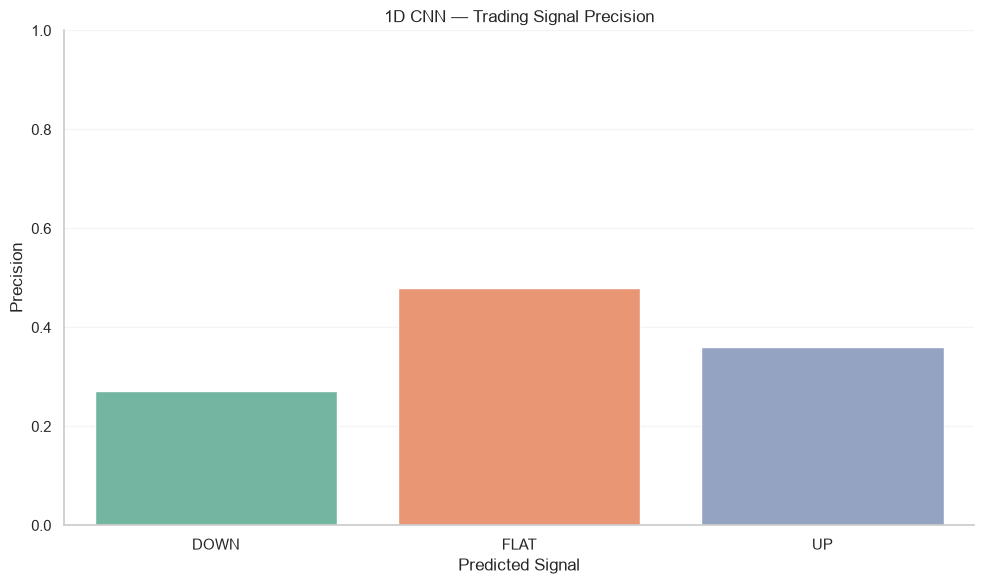

In [30]:
from sklearn.metrics import precision_score

probs = cnn_1d_weighted.predict(X_val, verbose=0)
y_pred = probs.argmax(axis=1)
rows = []

for class_id, name in enumerate(["DOWN", "FLAT", "UP"]):
    mask = y_pred == class_id

    rows.append({
        "Signal": name,
        "Predictions": mask.sum(),
        "Actual Frequency": (y_val == class_id).mean(),
        "Precision": (y_val[mask] == class_id).mean()
        if mask.sum() > 0 else np.nan,
        "Average Confidence": probs[mask, class_id].mean()
        if mask.sum() > 0 else np.nan
    })

signal_quality = pd.DataFrame(rows)

display(signal_quality.round(3))

fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=signal_quality,
    x="Signal",
    y="Precision",
    hue="Signal",
    palette="Set2",
    legend=False,
    ax=ax
)

ax.set_title("1D CNN — Trading Signal Precision")
ax.set_ylabel("Precision")
ax.set_xlabel("Predicted Signal")
ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

### 9.2 · Realized five-day returns by prediction

The recorded *mean forward returns* are **+0.423%** after `DOWN`, **+0.365%** after `FLAT`, and **+0.561%** after `UP` predictions. Even `DOWN` predictions are followed by positive mean returns in this sample. The positive `UP`–`DOWN` spread (~**0.138 percentage points**) is small and does **not** show that the strategy can capture negative regimes reliably. These windows **overlap**, so the means are descriptive and not independent trade outcomes.

,Observations,Mean_Return,Median_Return
Signal,,,
DOWN,985,0.423,0.523
FLAT,1247,0.365,0.404
UP,1807,0.561,0.604


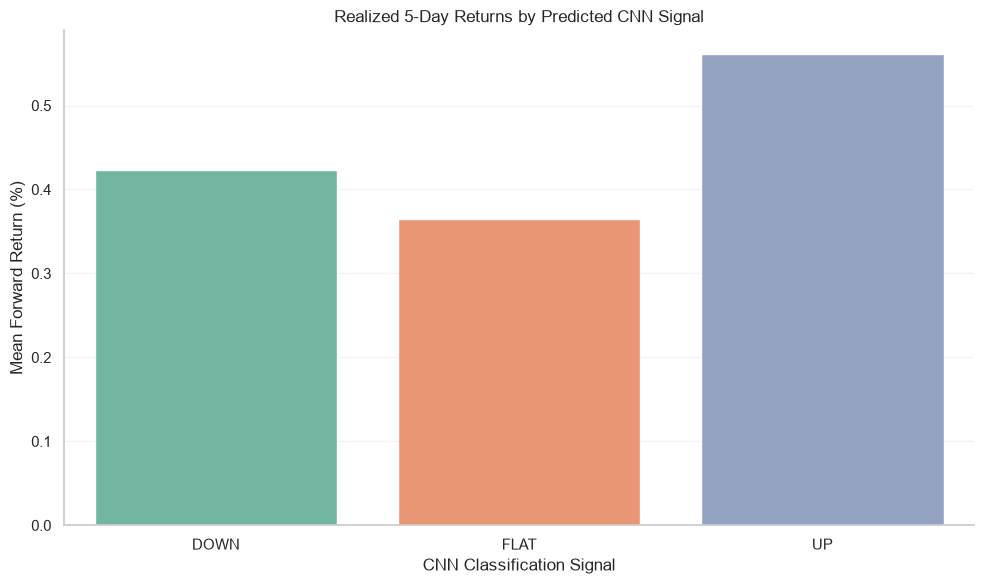

In [33]:

# Predicted signals from the weighted 1D CNN
val_probs = cnn_1d_weighted.predict(X_val, verbose=0)
val_pred = val_probs.argmax(axis=1)

signals_val = pd.DataFrame({
    "Ticker": splits["val"]["Ticker"],
    "Date": pd.to_datetime(splits["val"]["Date"]),
    "Predicted_Class": val_pred
})

signals_val = signals_val.merge(
    df[["Ticker", "Date", "future_return"]],
    on=["Ticker", "Date"],
    how="left",
    validate="one_to_one"
)

assert signals_val["future_return"].notna().all()

signals_val["Signal"] = signals_val["Predicted_Class"].map({
    0: "DOWN", 1: "FLAT", 2: "UP"
})

return_summary = (
    signals_val.groupby("Signal")
    .agg(
        Observations=("future_return", "size"),
        Mean_Return=("future_return", "mean"),
        Median_Return=("future_return", "median")
    )
    .reindex(["DOWN", "FLAT", "UP"])
)

return_summary[["Mean_Return", "Median_Return"]] *= 100

display(return_summary.round(3))

fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=return_summary.reset_index(),
    x="Signal",
    y="Mean_Return",
    hue="Signal",
    palette="Set2",
    legend=False,
    ax=ax
)

ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax.set_title("Realized 5-Day Returns by Predicted CNN Signal")
ax.set_ylabel("Mean Forward Return (%)")
ax.set_xlabel("CNN Classification Signal")

plt.tight_layout()
plt.show()


## 10 · Exploratory long/cash trading experiment (2022–2023)

We keep the **weighted 1D CNN** as a parsimonious trading example, although the 2D CNN ranks first by an immaterial margin. The classifier predicts using data available **through the close** of date $t$. Any position enters at the **next session's adjusted Open ($t+1$)** and exits at the **adjusted Close of $t+5$**. Decisions are approximately non-overlapping 5-session intervals **within each stock**; only an `UP` prediction triggers a long position. `FLAT` and `DOWN` remain in cash (no short selling).

**Costs:** an assumed **0.10% per side** (entry and exit), with no financing interest. The Buy & Hold benchmark is continuously long from the first entry to the final exit for each stock, with assumed one-time entry and exit costs.

> This is **exploratory validation-period** performance, not a deployable trading system. The trade horizon runs from next-day open to fifth-day close, rather than precisely the close-to-close horizon of the class target. Yahoo Finance `auto_adjust=True` produces adjusted price proxies, **not literal executable exchange prices**. No slippage, bid-ask spread, FX effects, tax, borrow cost or dividends reconciliation is modeled separately.

In [34]:

# Construct an execution schedule using actual OHLC prices.
# Predictions remain restricted to validation 2022–2023.

trade_rows = []

for ticker in TICKERS:

    prices = (
        df[df["Ticker"] == ticker]
        [["Date", "Open", "Close"]]
        .dropna()
        .sort_values("Date")
        .reset_index(drop=True)
    )

    date_lookup = {
        pd.Timestamp(date): i
        for i, date in enumerate(prices["Date"])
    }

    ticker_signals = (
        signals_val[signals_val["Ticker"] == ticker]
        .sort_values("Date")
    )

    last_exit_index = -1

    for _, row in ticker_signals.iterrows():

        signal_date = pd.Timestamp(row["Date"])
        i = date_lookup.get(signal_date)

        if i is None or i < last_exit_index:
            continue

        if i + HORIZON >= len(prices):
            continue

        entry_index = i + 1
        exit_index = i + HORIZON

        entry = prices.iloc[entry_index]
        exit_row = prices.iloc[exit_index]

        # Keep execution entirely within validation.
        if exit_row["Date"] >= TEST_START:
            continue

        trade_rows.append({
            "Ticker": ticker,
            "SignalDate": signal_date,
            "EntryDate": entry["Date"],
            "ExitDate": exit_row["Date"],
            "Predicted_Class": int(row["Predicted_Class"]),
            "EntryPrice": float(entry["Open"]),
            "ExitPrice": float(exit_row["Close"])
        })

        last_exit_index = exit_index

trade_windows = pd.DataFrame(trade_rows)

if trade_windows.empty:
    raise ValueError("No eligible validation trading windows.")

trade_windows = (
    trade_windows
    .sort_values(["Ticker", "SignalDate"])
    .reset_index(drop=True)
)

trade_windows["Signal"] = trade_windows["Predicted_Class"].map({
    0: "DOWN",
    1: "FLAT",
    2: "UP"
})

assert (
    trade_windows["EntryDate"] > trade_windows["SignalDate"]
).all()

assert (
    trade_windows["ExitDate"] < TEST_START
).all()

display(trade_windows.head(10))

print("Total non-overlapping decisions:", len(trade_windows))
print("\nSignal distribution:")
display(trade_windows["Signal"].value_counts())


,Ticker,SignalDate,EntryDate,ExitDate,Predicted_Class,EntryPrice,ExitPrice,Signal
0,ASML.AS,2022-01-03,2022-01-04,2022-01-10,2,677.738755,595.113342,UP
1,ASML.AS,2022-01-10,2022-01-11,2022-01-17,2,615.387191,627.532532,UP
2,ASML.AS,2022-01-17,2022-01-18,2022-01-24,2,619.690669,559.442993,UP
3,ASML.AS,2022-01-24,2022-01-25,2022-01-31,2,570.631876,568.240967,UP
4,ASML.AS,2022-01-31,2022-02-01,2022-02-07,2,578.569304,547.584717,UP
5,ASML.AS,2022-02-07,2022-02-08,2022-02-14,2,544.907103,535.248169,UP
6,ASML.AS,2022-02-14,2022-02-15,2022-02-21,2,529.606092,526.737061,UP
7,ASML.AS,2022-02-21,2022-02-22,2022-02-28,2,507.419478,572.735779,UP
8,ASML.AS,2022-02-28,2022-03-01,2022-03-07,2,570.727472,516.982727,UP
9,ASML.AS,2022-03-07,2022-03-08,2022-03-14,2,501.107855,511.149200,UP


Total non-overlapping decisions: 811

Signal distribution:


Signal
UP      372
FLAT    244
DOWN    195
Name: count, dtype: int64

### 10.1 · Trade scheduling

The scheduling code emits one candidate decision approximately every fifth trading session per ticker, **811 decisions across all eight stocks**. The uploaded execution contains **372 UP**, **244 FLAT**, and **195 DOWN** scheduled signals. These counts are decisions across separate assets, **not** 811 executed buys.

In [35]:

TRANSACTION_COST = 0.001

# Realized open-to-close return for each trading interval
trade_windows["Gross_Return"] = (
    trade_windows["ExitPrice"] /
    trade_windows["EntryPrice"] - 1
)

# Long-only: BUY only when the CNN predicts UP
trade_windows["Position"] = (
    trade_windows["Predicted_Class"] == 2
).astype(int)

# Apply entry and exit costs to executed positions only
trade_windows["Strategy_Return"] = np.where(
    trade_windows["Position"] == 1,
    (1 + trade_windows["Gross_Return"])
    * (1 - TRANSACTION_COST)**2 - 1,
    0.0
)

print("Trading strategy: Long / Cash")
print("Cost per transaction side:", TRANSACTION_COST * 100, "%")

preview = trade_windows[
    ["Ticker", "SignalDate", "Signal", "EntryDate", "ExitDate",
     "Gross_Return", "Strategy_Return"]
].head(12).copy()
preview[["Gross_Return", "Strategy_Return"]] = preview[
    ["Gross_Return", "Strategy_Return"]
].round(4)
display(preview)

# Build per-stock equity curves.
# Buy & Hold enters once, remains invested, exits once.
equity_parts = []

for ticker, stock in trade_windows.groupby("Ticker"):
    stock = stock.sort_values("ExitDate").copy()

    stock["Strategy_Wealth"] = (
        1 + stock["Strategy_Return"]
    ).cumprod()

    initial_entry = stock["EntryPrice"].iloc[0]

    stock["BuyHold_Wealth"] = (
        stock["ExitPrice"] / initial_entry
    ) * (1 - TRANSACTION_COST)**2

    equity_parts.append(stock)

equity_curves = pd.concat(equity_parts, ignore_index=True)

print("\nEquity curves calculated.")


Trading strategy: Long / Cash
Cost per transaction side: 0.1 %


,Ticker,SignalDate,Signal,EntryDate,ExitDate,Gross_Return,Strategy_Return
0,ASML.AS,2022-01-03,UP,2022-01-04,2022-01-10,-0.1219,-0.1237
1,ASML.AS,2022-01-10,UP,2022-01-11,2022-01-17,0.0197,0.0177
2,ASML.AS,2022-01-17,UP,2022-01-18,2022-01-24,-0.0972,-0.0990
3,ASML.AS,2022-01-24,UP,2022-01-25,2022-01-31,-0.0042,-0.0062
4,ASML.AS,2022-01-31,UP,2022-02-01,2022-02-07,-0.0536,-0.0554
5,ASML.AS,2022-02-07,UP,2022-02-08,2022-02-14,-0.0177,-0.0197
6,ASML.AS,2022-02-14,UP,2022-02-15,2022-02-21,-0.0054,-0.0074
7,ASML.AS,2022-02-21,UP,2022-02-22,2022-02-28,0.1287,0.1265
8,ASML.AS,2022-02-28,UP,2022-03-01,2022-03-07,-0.0942,-0.0960
9,ASML.AS,2022-03-07,UP,2022-03-08,2022-03-14,0.0200,0.0180



Equity curves calculated.


### 10.2 · Strategy accounting

`Strategy_Return` is zero in cash intervals and net of round-trip costs when an `UP` position is opened. The cumulative wealth series compounds non-overlapping per-ticker interval returns. The displayed "Market Exposure (%)" is the **share of scheduled decisions classified UP**, a simple proxy, not a precisely time-weighted exposure calculation. Drawdowns in the next cell are measured at sampled interval endpoints, not daily peaks and troughs.

In [36]:

performance_rows = []

for ticker, stock in equity_curves.groupby("Ticker"):

    stock = stock.sort_values("ExitDate")

    strategy_wealth = np.r_[
        1.0, stock["Strategy_Wealth"].to_numpy()
    ]

    buyhold_wealth = np.r_[
        1.0, stock["BuyHold_Wealth"].to_numpy()
    ]

    strategy_drawdown = (
        strategy_wealth /
        np.maximum.accumulate(strategy_wealth) - 1
    )

    buyhold_drawdown = (
        buyhold_wealth /
        np.maximum.accumulate(buyhold_wealth) - 1
    )

    performance_rows.append({
        "Ticker": ticker,
        "Decisions": len(stock),
        "Buy Trades": int(stock["Position"].sum()),
        "Market Exposure (%)": 100 * stock["Position"].mean(),
        "CNN Return (%)": 100 * (strategy_wealth[-1] - 1),
        "BuyHold Return (%)": 100 * (buyhold_wealth[-1] - 1),
        "CNN MaxDD (%)": 100 * strategy_drawdown.min(),
        "BuyHold MaxDD (%)": 100 * buyhold_drawdown.min()
    })

performance_df = (
    pd.DataFrame(performance_rows)
    .set_index("Ticker")
    .reindex(TICKERS)
)

performance_df["Excess Return (pp)"] = (
    performance_df["CNN Return (%)"] -
    performance_df["BuyHold Return (%)"]
)

display(performance_df.round(2))


,Decisions,Buy Trades,Market Exposure (%),CNN Return (%),BuyHold Return (%),CNN MaxDD (%),BuyHold MaxDD (%),Excess Return (pp)
Ticker,,,,,,,,
LDO.MI,101,49,48.51,24.32,134.25,-27.90,-32.19,-109.93
HO.PA,102,35,34.31,3.38,83.68,-16.03,-12.13,-80.30
PRY.MI,101,51,50.50,32.19,25.20,-12.88,-21.54,7.00
ASML.AS,102,70,68.63,10.23,-1.24,-33.88,-41.15,11.47
REP.MC,102,45,44.12,3.71,38.96,-20.01,-25.01,-35.24
UCG.MI,101,41,40.59,34.20,95.69,-38.68,-43.45,-61.49
SIE.DE,102,46,45.10,-15.44,15.34,-32.27,-36.12,-30.78
JPM,100,35,35.00,16.81,9.75,-18.64,-36.50,7.06


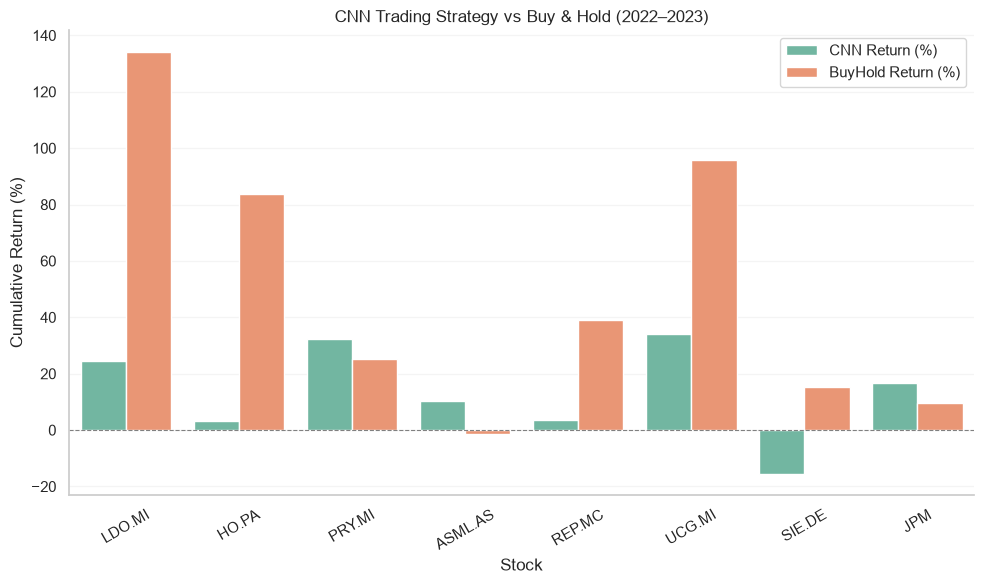

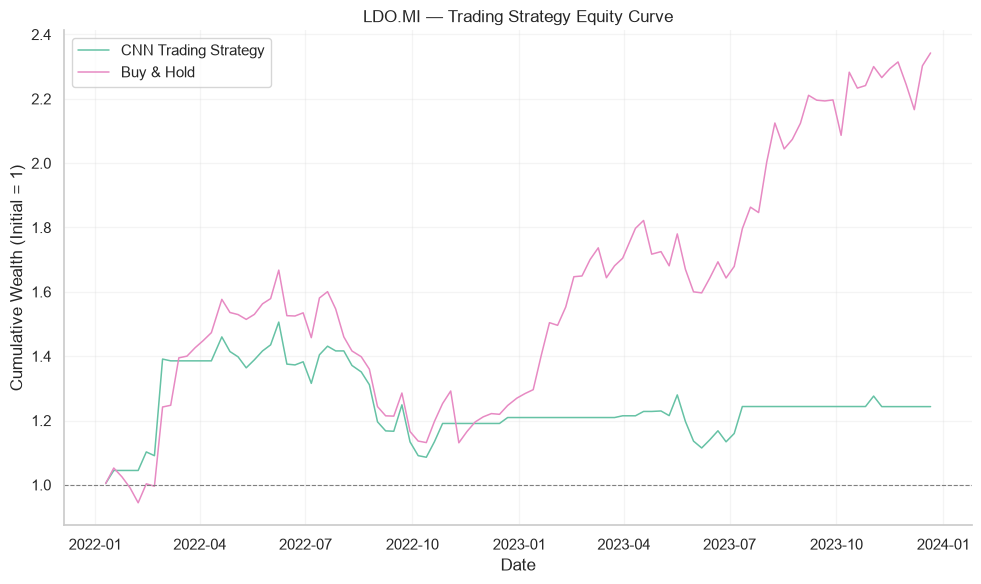

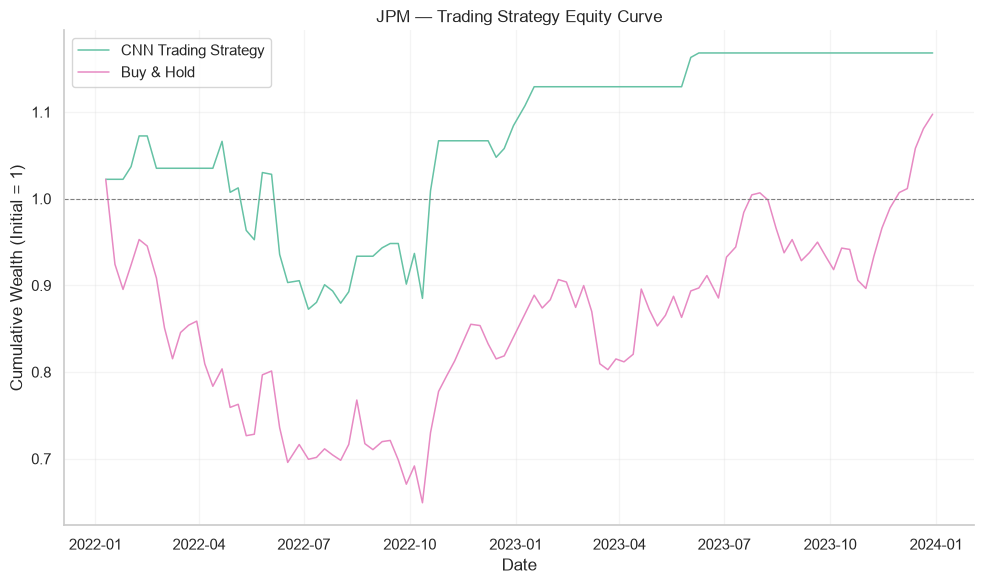


FINAL RESEARCH SUMMARY
Best validation model by Macro-F1:


,Model,Accuracy,Balanced Accuracy,Macro-F1
0,CNN 2D Weighted,0.3746,0.3663,0.364



Stocks where the CNN strategy exceeded Buy & Hold:
3 out of 8


In [ ]:

# Chart 1: Final returns across all stocks

plot_df = (
    performance_df
    .reset_index()
    .melt(
        id_vars="Ticker",
        value_vars=["CNN Return (%)", "BuyHold Return (%)"],
        var_name="Strategy",
        value_name="Return (%)"
    )
)

fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(data=plot_df,x="Ticker",y="Return (%)",hue="Strategy",palette="Set2",ax=ax)
ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax.set_title("CNN Trading Strategy vs Buy & Hold (2022–2023)")
ax.set_ylabel("Cumulative Return (%)")
ax.set_xlabel("Stock")
ax.legend(title="")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# Chart 2: Equity curves for Leonardo and JPMorgan

for ticker in ["LDO.MI", "JPM"]:

    stock = (
        equity_curves[equity_curves["Ticker"] == ticker]
        .sort_values("ExitDate")
    )

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.plot(stock["ExitDate"],stock["Strategy_Wealth"],label="CNN Trading Strategy",color=PALETTE[0],linewidth=1.1)
    ax.plot(stock["ExitDate"],stock["BuyHold_Wealth"],label="Buy & Hold",color=PALETTE[3],linewidth=1.1)
    ax.axhline(1, color="gray", linestyle="--", linewidth=0.8)
    ax.set_title(f"{ticker} — Trading Strategy Equity Curve")
    ax.set_xlabel("Date")
    ax.set_ylabel("Cumulative Wealth (Initial = 1)")
    ax.legend()
    plt.tight_layout()
    plt.show()

print("\nFINAL RESEARCH SUMMARY")
print("Best validation model by Macro-F1:")
display(comparison_df.head(1).round(4))

print("\nStocks where the CNN strategy exceeded Buy & Hold:")
print(
    int((performance_df["Excess Return (pp)"] > 0).sum()),
    "out of",
    len(performance_df)
)


## 11 · Final research findings

### Validation classification

| Model | Accuracy | Balanced accuracy | Macro-F1 |
|:--|--:|--:|--:|
| **CNN 2D Weighted** | 0.3746 | 0.3663 | **0.3640** |
| **CNN 1D Weighted** | 0.3758 | 0.3668 | 0.3637 |
| XGBoost | 0.4159 | **0.3695** | 0.3399 |
| CNN 1D | **0.4219** | 0.3636 | 0.2996 |
| Dummy | 0.4043 | 0.3333 | 0.1919 |

### Exploratory validation trading (weighted 1D CNN, 2022–2023)

| Stock | CNN long/cash return | Buy & Hold return | Difference (pp) |
|:--|--:|--:|--:|
| Leonardo | +24.32% | +134.25% | −109.93 |
| Thales | +3.38% | +83.68% | −80.30 |
| Prysmian | +32.19% | +25.20% | +7.00 |
| ASML | +10.23% | −1.24% | +11.47 |
| Repsol | +3.71% | +38.96% | −35.24 |
| UniCredit | +34.20% | +95.69% | −61.49 |
| Siemens | −15.44% | +15.34% | −30.78 |
| JPMorgan | +16.81% | +9.75% | +7.06 |

**3 of 8** individual stock comparisons favor the CNN strategy. Large underperformance in Leonardo, Thales and UniCredit dominates the narrative: a model that sometimes selects positive-return periods can still lose dramatically to passive exposure during strong uptrends. The test does not establish economic value or a generalizable edge.

### Answer to the research question

- **Representation learning:** Both 1D and 2D CNNs can extract numerical activations from rolling multivariate series, but activation maps alone do not establish interpretable financial patterns.
- **Classification:** Class weighting improves minority-class recall and Macro-F1 versus the unweighted CNN, but directional performance remains weak. The **1D and 2D variants are effectively tied**.
- **Trading value:** The selected 1D long/cash rule is not consistently superior to Buy & Hold across assets. Its performance is highly sensitive to market regime, exposure, horizon and the treatment of costs.

### Methodological limitations and next research priorities

1. **Validation reuse / selection bias:** Architecture, class weighting, and trading rules were explored on 2022–2023; the comparison is in-sample for design decisions even though these dates were not part of the initial training fit.
2. **Previously inspected 2024–2026:** Cannot claim it as a fresh, pristine holdout; genuine forward-only evaluation or pre-registered walk-forward splits would be required for confirmatory claims.
3. **Overlapping labels and model uncertainty:** Adjacent 5-session targets share prices; results are correlated. Additional random seeds, purged/embargoed splits where appropriate, and confidence intervals accounting for dependence are needed.
4. **2D feature geometry:** The order of the eight features is arbitrary. A feature-order permutation test should precede any claim about superior 2D representations.
5. **Threshold heterogeneity:** ±2% has a different economic meaning for semiconductor, defense and banking stocks; volatility-scaled thresholds could be tested as a **new, separately evaluated experiment**.
6. **Backtest realism:** Adjusted OHLC are research proxies; spreads, slippage, corporate actions, exchange-rate changes, variable costs, exact daily mark-to-market and appropriate risk-adjusted benchmarks remain out of scope.

### References

- Sezer, O. B., & Ozbayoglu, A. M. (2018). *Algorithmic financial trading with deep convolutional neural networks: Time series to image conversion approach*. **Applied Soft Computing, 70**, 525–538. https://doi.org/10.1016/j.asoc.2018.04.024
- Ismail Fawaz, H., et al. (2019). *Deep learning for time series classification: a review*. **Data Mining and Knowledge Discovery, 33**, 917–963. https://doi.org/10.1007/s10618-019-00619-1

**Scope statement:** Independent educational research case study inspired by the literature. This is **not** an exact replication of Sezer & Ozbayoglu's 15×15 indicator-grid method, and should not be interpreted as investment advice.